# 05 - How much do the headline numbers depend on the method?

Notebook 02 asks: *does the flood map agree with Copernicus EMS?* This notebook asks a different question: **if we make a different (but reasonable) choice in the method, how much do the final numbers change?**

We change one choice at a time (`SCENARIOS` in `src/flood.py`) and recompute the total flooded area and the flooded cropland (ESA WorldCover class 40) for the peak of the flood.
Only Earth Engine is needed, no local data. Areas are computed on a 30 m grid for speed, so the baseline can differ slightly from notebooks 01 and 04, which use 10 m pixels and municipal boundaries. Compare the *changes*, not the absolute values.

In [1]:
import sys
from pathlib import Path
import ee
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Your Earth Engine project id lives in project_id.txt (project root, not uploaded to GitHub)
_pid_file = Path.cwd().parent / "project_id.txt"
PROJECT_ID = _pid_file.read_text().strip() if _pid_file.exists() else "your-gcp-project-id"
ee.Initialize(project=PROJECT_ID)

ROOT = Path.cwd().parent
sys.path.append(str(ROOT))
from src.flood import get_aoi, peak_flood, SCENARIOS

aoi = get_aoi()
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)

cropland = ee.ImageCollection("ESA/WorldCover/v200").first().select("Map").eq(40).unmask(0)
px = ee.Image.pixelArea().divide(1e6)       # km² per pixel
SCALE = 30

def areas(params):
    flood, _ = peak_flood(aoi, **params)
    f = flood.unmask(0)
    img = ee.Image.cat([f.multiply(px).rename("total"),
                        f.And(cropland).multiply(px).rename("cropland")])
    r = img.reduceRegion(ee.Reducer.sum(), aoi, SCALE, maxPixels=1e10, bestEffort=True, tileScale=4).getInfo()
    return r["total"], r["cropland"]

## 1. Run the scenarios

Each scenario runs the whole method twice (12 and 13 September), so this can take a while.

In [2]:
rows = []
for label, params in SCENARIOS.items():
    try:
        total, crop = areas(params)
        rows.append({"scenario": label, "total_km2": total, "cropland_km2": crop})
        print(f"{label:<28} total {total:7.1f} km²   cropland {crop:7.1f} km²")
    except Exception as e:
        print(f"{label:<28} FAILED: {e}")

res = pd.DataFrame(rows).set_index("scenario")
base = res.loc["baseline"]
res["total_change_%"] = (res["total_km2"] / base["total_km2"] - 1) * 100
res["cropland_change_%"] = (res["cropland_km2"] / base["cropland_km2"] - 1) * 100
res.to_csv(OUT / "robustness_of_results.csv")
res.round(1)

baseline                     total   333.8 km²   cropland   296.2 km²
change < -2 dB               total   359.8 km²   cropland   314.6 km²
change < -4 dB               total   312.7 km²   cropland   280.8 km²
post < -13 dB                total   358.9 km²   cropland   316.9 km²
post < -17 dB                total   298.2 km²   cropland   266.3 km²
speckle filter 30 m          total   337.4 km²   cropland   298.9 km²
speckle filter 80 m          total   326.9 km²   cropland   289.8 km²
min cluster 4 px             total   340.3 km²   cropland   300.8 km²
min cluster 16 px            total   325.5 km²   cropland   290.2 km²
max slope 3°                 total   293.9 km²   cropland   263.8 km²
max slope 10°                total   339.7 km²   cropland   299.5 km²
before-window from 1 Aug     total   337.1 km²   cropland   297.5 km²
before-window from 1 Jul     total   340.4 km²   cropland   300.5 km²
before-window 25 Aug–4 Sep   total   335.7 km²   cropland   296.7 km²


,total_km2,cropland_km2,total_change_%,cropland_change_%
scenario,,,,
baseline,333.8,296.2,0.0,0.0
change < -2 dB,359.8,314.6,7.8,6.2
change < -4 dB,312.7,280.8,-6.3,-5.2
post < -13 dB,358.9,316.9,7.5,7.0
post < -17 dB,298.2,266.3,-10.7,-10.1
speckle filter 30 m,337.4,298.9,1.1,0.9
speckle filter 80 m,326.9,289.8,-2.1,-2.2
min cluster 4 px,340.3,300.8,2.0,1.6
min cluster 16 px,325.5,290.2,-2.5,-2.0


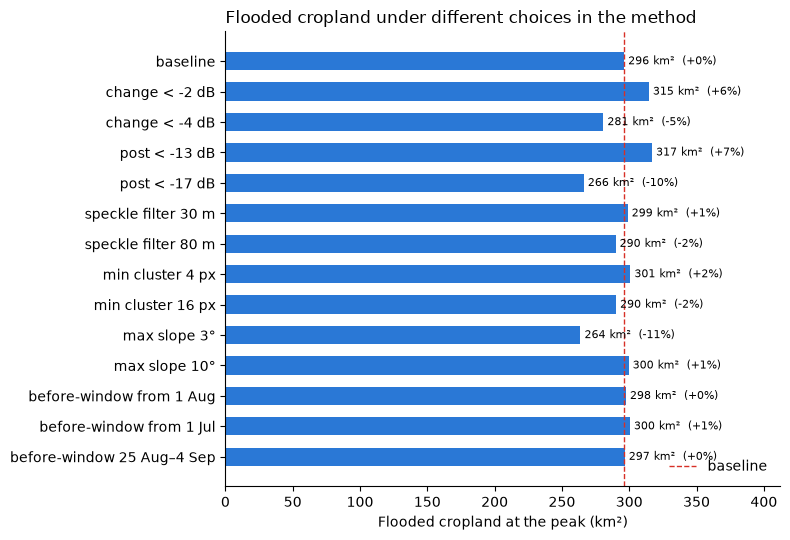

In [3]:
fig, ax = plt.subplots(figsize=(8, 5.5))
y = np.arange(len(res))
ax.barh(y, res["cropland_km2"], color="#2a78d6", height=0.6)
ax.axvline(base["cropland_km2"], color="#d73027", ls="--", lw=1, label="baseline")
for i, (v, p) in enumerate(zip(res["cropland_km2"], res["cropland_change_%"])):
    ax.text(v + 3, i, f"{v:.0f} km²  ({p:+.0f}%)", va="center", fontsize=8)
ax.set_yticks(y, res.index); ax.invert_yaxis()
ax.set_xlim(0, res["cropland_km2"].max() * 1.3)
ax.set_xlabel("Flooded cropland at the peak (km²)")
ax.set_title("Flooded cropland under different choices in the method", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(OUT / "robustness_of_results.png", dpi=150)
plt.show()

In [4]:
others = res.drop(index="baseline")
lo, hi = others["cropland_km2"].min(), others["cropland_km2"].max()
print(f"Baseline flooded cropland: {base['cropland_km2']:.0f} km²")
print(f"Range over all scenarios:  {lo:.0f} – {hi:.0f} km²  ({lo / base['cropland_km2'] - 1:+.0%} to {hi / base['cropland_km2'] - 1:+.0%})")
print()
print("Choices that matter most (largest change):")
print(others["cropland_change_%"].abs().sort_values(ascending=False).head(5).round(1))

Baseline flooded cropland: 296 km²
Range over all scenarios:  264 – 317 km²  (-11% to +7%)

Choices that matter most (largest change):
scenario
max slope 3°      11.0
post < -17 dB     10.1
post < -13 dB      7.0
change < -2 dB     6.2
change < -4 dB     5.2
Name: cropland_change_%, dtype: float64


## How to read this

* **Small changes** (a few percent) mean the headline number does not depend on that particular choice.
* **Large changes** show which choices drive the result. Report them as a range, not as a single number.
* This is **not** a measure of accuracy. All scenarios share the same blind spots of SAR (shallow water under crops, built-up areas), so the truth can lie outside the range. Accuracy against an independent reference is tested in notebook 02.